# Python Notebook to demonstrate Vibration Mode Recognition Using A Combination Of DSP And Machine Learning

## This example supports an arbitrary number of categories and features

This program downloads an arbitrary number of .wav file recordings of rotating machines, then uses a subset of data from each file to train a Convolutional Neural Network (CNN) to recognize the different vibration modes and tests the model using a further subset of the data.

.wav file recordings can be downloaded from a website URL (GitHub Raw User Content) or copied from Google Drive /wav_files folder.

Prior to the CNN, each waveform is converted to **log-Mel filterbank features** using:

**frame → Hann window → FFT → |X[k]|² → Mel filters → natural log**

The frontend uses 256-sample non-overlapping frames, a 512-point real FFT, and 40 Mel filters. The CNN therefore has 40 input nodes, one for each log-Mel band.

This file trains and tests the model. It also generates TensorFlow Lite and 8-bit quantized TensorFlow Lite models and tests the quantized model.

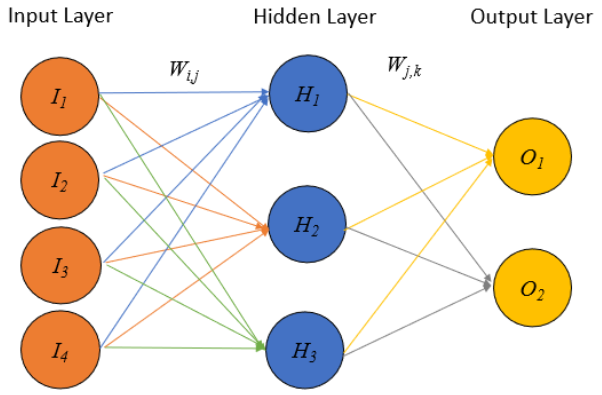

SigLib DSP Library can be downloaded from: https://github.com/Numerix-DSP/siglib

Sigma Numerix Ltd. Machine Learning capabilities are summarized here: https://numerix-dsp.com/ai/

**License**

This program is free software: you can redistribute it and/or modify 
it under the terms of the GNU General Public License as published by 
the Free Software Foundation, version 3.

This program is distributed in the hope that it will be useful, but 
WITHOUT ANY WARRANTY; without even the implied warranty of 
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU 
General Public License for more details.

You should have received a copy of the GNU General Public License 
along with this program. If not, see <http://www.gnu.org/licenses/>.

Copyright © 2026 Delta Numerix All rights reserved.


In [1]:
import numpy as np
import tensorflow as tf
import os

from matplotlib import pyplot as plt
from scipy.io import wavfile
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix


I0000 00:00:1786431179.087919   58313 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786431179.122794   58313 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Top level configuration

# .wav file sampling rate = 16 kHz
# Frame size = 256 samples
# Frame period = 16 ms

timeDomainFrameLength = 256
timeDomainFrameHop = 256       # Non-overlapping frames
fftLength = 512                # Zero-pad each 256-sample frame for Mel filter resolution
numMelFilters = 40
melMinFrequency = 20.0
melMaxFrequency = None         # None selects Nyquist
windowName = "hann"
logScale = "ln"
logFloor = 1e-10

# CNN input width is now the number of log-Mel bands.
networkInputLayerNodes = numMelFilters

# Download the .wav files from the SigLib GitHub repository
masterUrlRoot = 'https://raw.githubusercontent.com/Numerix-DSP/siglib/main/Examples/CExamples/MachineLearning/sourceData/'

# Input filenames:
wavFilenames = [
  'Machine1.wav',
  'Machine2.wav',
  # 'Machine3.wav',
  # 'Machine4.wav',
]

numClasses = len(wavFilenames)
print(f'numClasses: {numClasses}')


numClasses: 2


In [3]:
# Load .wav files and create a list containing all wav datasets

wavData = []
wavSampleRates = []

for i in range(0, numClasses):
  if (os.path.exists(wavFilenames[i]) != True):          # If files are stored locally, we can skip this
    fileurl = masterUrlRoot + wavFilenames[i]
    print(f'Loading fileurl: {fileurl}')
    if 'https://' in fileurl:
      !wget -arg1 $fileurl
    else:
      !cp $fileurl .

  sampleRate, wd = wavfile.read(wavFilenames[i])
  wavData.append(wd)
  wavSampleRates.append(sampleRate)

  print(f'len(wavData{i}): {len(wavData[i])}')
  print(f'Sample Rate: {sampleRate}')


len(wavData0): 3023499
Sample Rate: 16000
len(wavData1): 2852709
Sample Rate: 16000


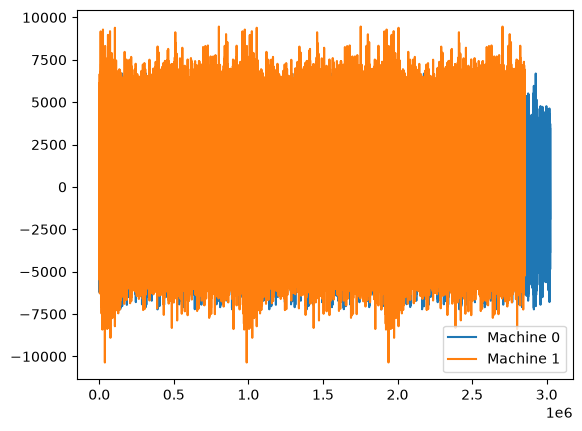

In [4]:
# Plot data to verify it

plt.figure()
for i in range(0, numClasses):
  plt.plot(wavData[i], label=f'Machine {i}')
plt.legend(loc="best")
plt.show()
plt.close()


In [5]:
# Framing is performed inside log_mel_frontend().
# Keep each source waveform as a 1-D array so the complete pipeline is:
# frame -> window -> FFT -> |X[k]|^2 -> Mel filters -> log

print('Waveforms will be framed inside the log-Mel frontend.')


Waveforms will be framed inside the log-Mel frontend.


In [6]:
# Log-Mel DSP front end
# Pipeline: frame -> window -> FFT -> |X[k]|^2 -> Mel filters -> log

def hz_to_mel(f_hz):
  """Convert frequency in Hz to HTK Mel scale."""
  return 2595.0 * np.log10(1.0 + np.asarray(f_hz) / 700.0)


def mel_to_hz(m_mel):
  """Convert HTK Mel scale to frequency in Hz."""
  return 700.0 * (10.0 ** (np.asarray(m_mel) / 2595.0) - 1.0)


def frame_signal(x, frame_length, hop_length):
  """Split a 1-D signal into overlapping frames and zero-pad the tail."""
  if len(x) <= frame_length:
    n_frames = 1
  else:
    n_frames = 1 + int(np.ceil((len(x) - frame_length) / hop_length))

  total_length = (n_frames - 1) * hop_length + frame_length
  x_padded = np.pad(x, (0, max(0, total_length - len(x))))

  starts = np.arange(n_frames)[:, None] * hop_length
  offsets = np.arange(frame_length)[None, :]
  return x_padded[starts + offsets]


def get_window(name, length):
  """Return the requested analysis window."""
  if name == "hann":
    return np.hanning(length).astype(np.float32)
  if name == "hamming":
    return np.hamming(length).astype(np.float32)
  if name == "rect":
    return np.ones(length, dtype=np.float32)
  raise ValueError(f"Unsupported window: {name}")


def create_mel_filterbank(sample_rate, n_fft, n_mels, fmin, fmax):
  """Construct a triangular Mel filterbank."""
  n_bins = n_fft // 2 + 1

  mel_points = np.linspace(
    hz_to_mel(fmin),
    hz_to_mel(fmax),
    n_mels + 2,
  )
  hz_points = mel_to_hz(mel_points)

  bin_points = np.floor(
    (n_fft + 1) * hz_points / sample_rate
  ).astype(int)
  bin_points = np.clip(bin_points, 0, n_bins - 1)

  filters = np.zeros((n_mels, n_bins), dtype=np.float32)

  for m in range(1, n_mels + 1):
    left = bin_points[m - 1]
    centre = bin_points[m]
    right = bin_points[m + 1]

    if centre > left:
      k = np.arange(left, centre)
      filters[m - 1, k] = (k - left) / (centre - left)

    if right > centre:
      k = np.arange(centre, right)
      filters[m - 1, k] = (right - k) / (right - centre)

  return filters


def log_mel_frontend(
  x,
  sample_rate,
  frame_length=timeDomainFrameLength,
  hop_length=timeDomainFrameHop,
  n_fft=fftLength,
  n_mels=numMelFilters,
  fmin=melMinFrequency,
  fmax=melMaxFrequency,
  window_name=windowName,
  log_scale=logScale,
  floor=logFloor,
):
  """
  frame -> window -> FFT -> |X[k]|^2 -> Mel filters -> log

  Returns
  -------
  log_mel : ndarray, shape (n_frames, n_mels)
  """
  x = np.asarray(x)

  if x.ndim == 2:
    x = x.astype(np.float32).mean(axis=1)
  elif x.ndim != 1:
    raise ValueError("Expected a mono or stereo waveform.")

  # Convert integer WAV samples to approximately [-1, 1].
  if np.issubdtype(x.dtype, np.integer):
    info = np.iinfo(x.dtype)
    scale = max(abs(info.min), info.max)
    x = x.astype(np.float32) / scale
  else:
    x = x.astype(np.float32)

  if fmax is None:
    fmax = sample_rate / 2.0

  nyquist = sample_rate / 2.0
  if not (0.0 <= fmin < fmax <= nyquist):
    raise ValueError(
      f"Require 0 <= fmin < fmax <= Nyquist ({nyquist:.1f} Hz)."
    )

  if frame_length < 1 or hop_length < 1:
    raise ValueError("frame_length and hop_length must be at least one sample.")

  if n_fft < frame_length:
    raise ValueError(
      f"n_fft={n_fft} is smaller than frame_length={frame_length}."
    )

  # 1. Frame
  frames = frame_signal(x, frame_length, hop_length)

  # 2. Window
  window = get_window(window_name, frame_length)
  windowed = frames * window[None, :]

  # 3. FFT - rFFT returns bins from D.C. through Nyquist
  X = np.fft.rfft(windowed, n=n_fft, axis=1)

  # 4. Power spectrum |X[k]|^2
  power = X.real**2 + X.imag**2

  # 5. Mel filters
  mel_filters = create_mel_filterbank(
    sample_rate=sample_rate,
    n_fft=n_fft,
    n_mels=n_mels,
    fmin=fmin,
    fmax=fmax,
  )
  mel_energy = power @ mel_filters.T

  # 6. Log compression
  mel_energy = np.maximum(mel_energy, floor)

  if log_scale == "ln":
    log_mel = np.log(mel_energy)
  elif log_scale == "log10":
    log_mel = np.log10(mel_energy)
  elif log_scale == "db":
    log_mel = 10.0 * np.log10(mel_energy)
  else:
    raise ValueError(f"Unsupported log scale: {log_scale}")

  return log_mel.astype(np.float32)


In [7]:
# Process each waveform into one log-Mel feature vector per frame

wav_logmel_2D_list = []

for i in range(0, numClasses):
  log_mel = log_mel_frontend(
    x=wavData[i],
    sample_rate=wavSampleRates[i],
  )
  wav_logmel_2D_list.append(log_mel)
  print(f'wav_logmel_2D_list[{i}] shape: {wav_logmel_2D_list[i].shape}')


wav_logmel_2D_list[0] shape: (11811, 40)
wav_logmel_2D_list[1] shape: (11144, 40)


In [8]:
# Split into training/validation (90%) and testing (10%) datasets

def split_array_train_test(wav_array, train_percentage):
  train_len = (len(wav_array) * train_percentage) // 100
  return wav_array[:train_len], wav_array[train_len:]

wav_xtrain = []
wav_xtest = []

for i in range(0, numClasses):
  wr, wt = split_array_train_test(wav_logmel_2D_list[i], 90)
  wav_xtrain.append(wr)
  wav_xtest.append(wt)

  print(f'wav{i} # subframes: {len(wav_logmel_2D_list[i])}')
  print(f'wav{i} train shape: {wav_xtrain[i].shape}')
  print(f'wav{i} test shape: {wav_xtest[i].shape}')


wav0 # subframes: 11811
wav0 train shape: (10629, 40)
wav0 test shape: (1182, 40)
wav1 # subframes: 11144
wav1 train shape: (10029, 40)
wav1 test shape: (1115, 40)


In [9]:
# Create X and Y datasets for training, testing and validation

X_train = wav_xtrain[0]
X_test = wav_xtest[0]
for i in range(1, numClasses):
  X_train = np.concatenate((X_train, wav_xtrain[i]), axis=0)
  X_test = np.concatenate((X_test, wav_xtest[i]), axis=0)

# Create labels
wav_ytrain = []
wav_ytest = []
for i in range(0, numClasses):
  wav_ytrain.append(np.full(len(wav_xtrain[i]), i))
  wav_ytest.append(np.full(len(wav_xtest[i]), i))

y_train = wav_ytrain[0]
y_test = wav_ytest[0]
for i in range(1, numClasses):
  y_train = np.concatenate((y_train, wav_ytrain[i]), axis=0)
  y_test = np.concatenate((y_test, wav_ytest[i]), axis=0)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')


X_train shape: (20658, 40)
y_train shape: (20658,)
X_test shape: (2297, 40)
y_test shape: (2297,)


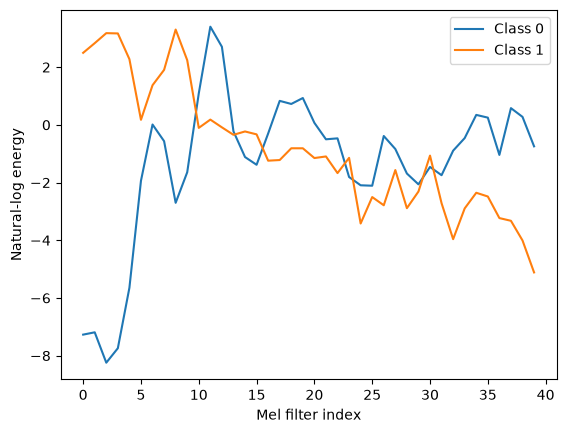

In [10]:
# Plot an arbitrary log-Mel frame (100) of each class

plt.figure()
for c in range(numClasses):
  c_X_train = X_train[y_train == c]
  plt.plot(c_X_train[100], label="Class " + str(c))

plt.xlabel("Mel filter index")
plt.ylabel("Natural-log energy")
plt.legend(loc="best")
plt.show()
plt.close()


In [11]:
# Reshape for Keras

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')


X_train shape: (20658, 40, 1)
X_test shape: (2297, 40, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 40, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1, 32)          │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378 (5.38 KB)

 Trainable params: 1,378 (5.38 KB)

 Non-trainable params: 0 (0.00 B)

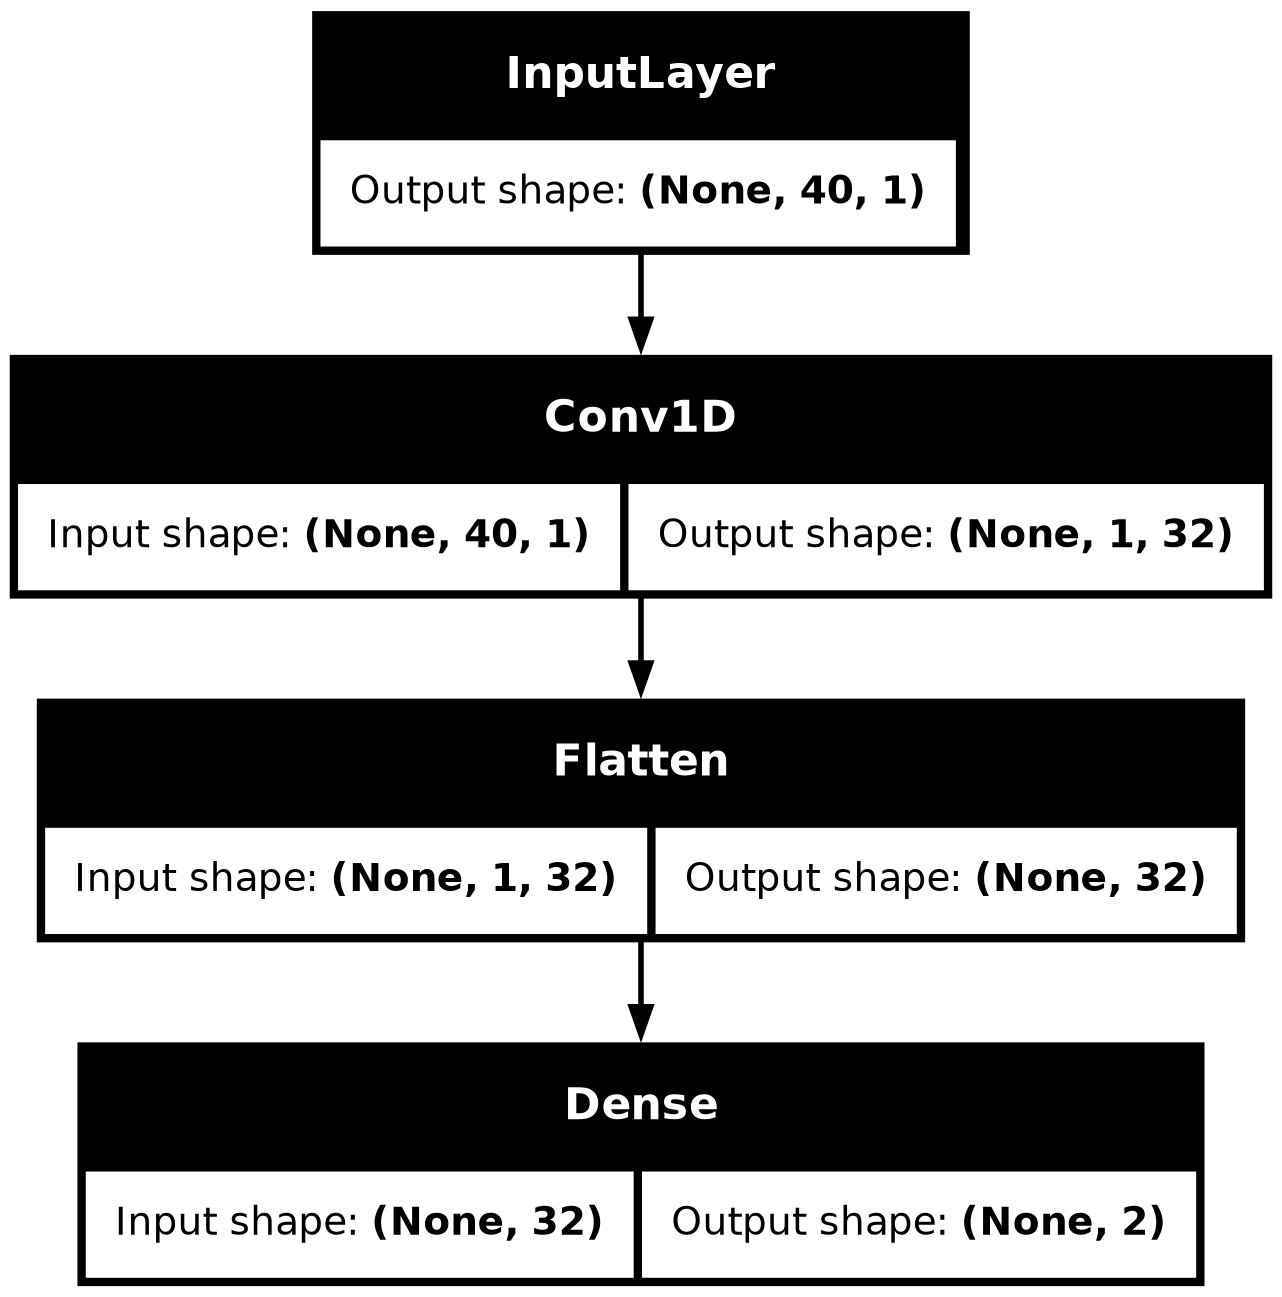

In [12]:
# Time Series Classification Model
input_layer = tf.keras.layers.Input(shape=(networkInputLayerNodes,1))

conv1 = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=networkInputLayerNodes,
    activation='relu',
    use_bias=True
)(input_layer)
flatten = tf.keras.layers.Flatten()(conv1)
output_layer = tf.keras.layers.Dense(
    numClasses,
    activation="softmax",
    use_bias=True
)(flatten)

# x = tf.keras.layers.Conv1D(filters=32,
#                            kernel_size=networkInputLayerNodes,
#                            activation='relu',
#                            use_bias=True)(input_layer)
# x = tf.keras.layers.GlobalMaxPooling1D()(x)  # or GlobalAveragePooling1D(), or Flatten()
# output_layer = tf.keras.layers.Dense(numClasses,
#                                     #  activation="sigmoid",
#                                      activation="softmax",
#                                      use_bias=True)(x)

model_tsc = tf.keras.models.Model(inputs=input_layer, outputs=output_layer)

model_tsc.summary()
tf.keras.utils.plot_model(model_tsc, show_shapes=True)


In [13]:
# Train the model

callbacks = [
  tf.keras.callbacks.ModelCheckpoint(
    "best_log_mel_model.h5",
    save_best_only=True,
    monitor="val_loss"
  )
]

model_tsc.compile(
  optimizer="adam",
  loss="sparse_categorical_crossentropy",
  metrics=["sparse_categorical_accuracy"])

history = model_tsc.fit(
  X_train,
  y_train,
  batch_size=32,
  epochs=4,
  shuffle=True,
  callbacks=callbacks,
  validation_split=0.2,
  verbose=1)


Epoch 1/4
506/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0123 - sparse_categorical_accuracy: 0.9954

517/517 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0120 - sparse_categorical_accuracy: 0.9955 - val_loss: 1.3536e-04 - val_sparse_categorical_accuracy: 1.0000
Epoch 2/4
505/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.4727e-05 - sparse_categorical_accuracy: 1.0000

517/517 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4.3989e-05 - sparse_categorical_accuracy: 1.0000 - val_loss: 2.4344e-05 - val_sparse_categorical_accuracy: 1.0000
Epoch 3/4
504/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2354e-05 - sparse_categorical_accuracy: 1.0000

517/517 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.2179e-05 - sparse_categorical_accuracy: 1.0000 - val_loss: 1.2201e-05 - val_sparse_categorical_accuracy: 1.0000
Epoch 4/4
513/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5.8058e-06 - sparse_categorical_accuracy: 1.0000

517/517 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 5.7879e-06 - sparse_categorical_accuracy: 1.0000 - val_loss: 7.0984e-06 - val_sparse_categorical_accuracy: 1.0000


In [14]:
# Test the model

model_tsc = tf.keras.models.load_model("best_log_mel_model.h5")
test_loss, test_acc = model_tsc.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')
print(f'Test loss:     {test_loss}')


72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.2027e-04 - sparse_categorical_accuracy: 1.0000
Test accuracy: 1.0
Test loss:     0.00022027213708497584


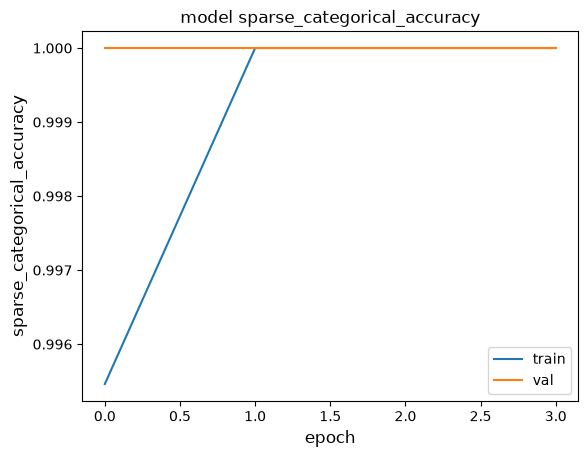

In [15]:
# Plot the accuracy as the CNN trains

metric = "sparse_categorical_accuracy"
plt.figure()
plt.plot(history.history[metric])
plt.plot(history.history["val_" + metric])
plt.title("model " + metric)
plt.ylabel(metric, fontsize="large")
plt.xlabel("epoch", fontsize="large")
plt.legend(["train", "val"], loc="best")
plt.rcParams["figure.figsize"] = 12,5
plt.show()
plt.close()


72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
y_pred shape: (2297, 2)
y_test shape: (2297,)
y_pred shape: (2297,)


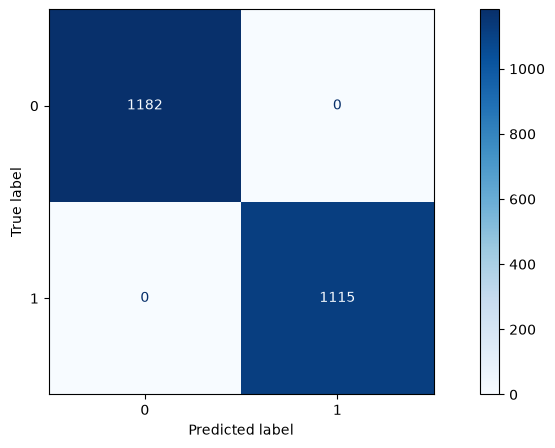

In [16]:
# Generate a confusion matrix to see which classes perform well or poorly
y_pred = model_tsc.predict(X_test)          # Returns probabilities

print(f'y_pred shape: {y_pred.shape}')

y_pred = np.argmax(y_pred, axis=-1)         # Return the index of the prediction with highest probability
print(f'y_test shape: {y_test.shape}')
print(f'y_pred shape: {y_pred.shape}')

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.rcParams["figure.figsize"] = 12,5
plt.show()


In [17]:
# Convert to a TensorFlow Lite model for deployment on a microcontroller

converter = tf.lite.TFLiteConverter.from_keras_model(model_tsc)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_model = converter.convert()

open("tsc_log_mel.tflite", "wb").write(tflite_model)


INFO:tensorflow:Assets written to: /tmp/tmpf5pdw4he/assets


INFO:tensorflow:Assets written to: /tmp/tmpf5pdw4he/assets


Saved artifact at '/tmp/tmpf5pdw4he'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140117416452624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449168: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1786431200.776850   58313 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1786431200.776892   58313 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1786431200.777453   58313 reader.cc:83] Reading SavedModel from: /tmp/tmpf5pdw4he
I0000 00:00:1786431200.777900   58313 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1786431200.777910   58313 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpf5pdw4he
I0000 00:00:1786431200.782239   58313 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1786431200.782733   58313 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1786431200.801942   58313 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpf5pdw4he
I0000 00:00:1786431200.806213   58313 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 28790 microseconds.
I0000 00:00:1786431200.823378   58313

9200

In [18]:
# Generate a quantized TensorFlow Lite model

def representative_data_gen():
  for input_value in tf.data.Dataset.from_tensor_slices(
      X_train.astype('float32')).batch(1).take(100):
    yield [input_value]

converter = tf.lite.TFLiteConverter.from_keras_model(model_tsc)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

tflite_model_quant = converter.convert()
open("tsc_log_mel_quant.tflite", "wb").write(tflite_model_quant)


INFO:tensorflow:Assets written to: /tmp/tmp7izcn1f8/assets


INFO:tensorflow:Assets written to: /tmp/tmp7izcn1f8/assets


Saved artifact at '/tmp/tmp7izcn1f8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140117416452624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140117416449168: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/johne/anaconda3/lib/python3.13/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1786431201.077900   58313 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1786431201.077943   58313 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1786431201.078084   58313 reader.cc:83] Reading SavedModel from: /tmp/tmp7izcn1f8
I0000 00:00:1786431201.078346   58313 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1786431201.078351   58313 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp7izcn1f8
I0000 00:00:1786431201.080463   58313 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1786431201.094329   58313 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp7izcn1f8
I0000 00:00:1786431201.098966   58313 loader.cc:471] SavedModel load for tags { ser

6664

In [19]:
interpreter = tf.lite.Interpreter(model_path="tsc_log_mel_quant.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_scale, input_zero_point = input_details[0]['quantization']
if input_scale == 0:
  raise ValueError("Invalid TFLite input quantization scale.")

error_count = 0
num_test_sequences = X_test.shape[0]

print(f'num_test_sequences: {num_test_sequences}')
print(f'Max: {np.amax(X_test):.2f}')
print(f'Min: {np.amin(X_test):.2f}')
print(f'Input quantization scale: {input_scale}')
print(f'Input quantization zero point: {input_zero_point}')

for i in range(0, num_test_sequences):
  X_temp = X_test[i].reshape(1, networkInputLayerNodes, 1)

  # Quantize float log-Mel features using the calibration parameters
  # generated by the representative dataset.
  input_data = np.round(X_temp / input_scale + input_zero_point)
  input_data = np.clip(input_data, 0, 255).astype(np.uint8)

  interpreter.set_tensor(input_details[0]['index'], input_data)
  interpreter.invoke()

  output_data = interpreter.get_tensor(output_details[0]['index'])
  maxIndex = np.argmax(output_data)

  if maxIndex != y_test[i]:
    error_count += 1

print(f'error_count:   {error_count}')
print(f'Test accuracy: {(num_test_sequences-error_count)*100./num_test_sequences:.2f}')
print(f'Test loss:     {error_count*100./num_test_sequences:.2f}')


num_test_sequences: 2297
Max: 5.03
Min: -10.26
Input quantization scale: 0.05466225743293762
Input quantization zero point: 172


/home/johne/anaconda3/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


error_count:   0
Test accuracy: 100.00
Test loss:     0.00
